# Features ao longo do tempo

O gráfico de cada feature extraída por `src/features.py`, para cada faixa de teste.

No fim, os sinais sintéticos servem de conferência. A varredura deve produzir um centroide crescente, e a trilha de cliques, picos de onset a cada 0,5 s.

As features vêm de `load_features`: a primeira execução calcula e grava o cache em `data/cache/`, e as seguintes só leem.

## O que queremos observar

A ideia do projeto é que cada característica do som controle uma propriedade do movimento das partículas. Para isso funcionar, cada feature precisa:

1. **medir o que achamos que ela mede**, ou seja, responder ao que ouvimos na música;
2. **variar de forma visível ao longo do tempo**, mas sem tremer tanto a ponto de deixar o movimento nervoso.

Os gráficos servem para conferir essas duas coisas. Para cada feature, a pergunta é a seguinte:

- **Intensidade (RMS)**: o volume do som em cada instante. Queremos ver a curva subir nas partes fortes e cair nas partes fracas e no silêncio. Ela vai controlar o quanto as partículas se agitam.
- **Centroide espectral**: o "centro de gravidade" das frequências, que diz se o som está mais grave ou mais agudo e brilhante. Queremos ver a curva subir quando a música fica mais aguda. Ele vai decidir se a nuvem sobe ou desce.
- **Largura de banda e rolloff**: o quanto as frequências se espalham em torno do centroide, e até onde vai a maior parte (85%) da energia. Completam a descrição do timbre: um som "cheio" tem banda larga, e um som puro, banda estreita.
- **Planicidade espectral**: se o som tem notas definidas (perto de 0) ou se parece com um chiado (perto de 1). Queremos ver valores baixos em instrumentos melódicos e altos em ruído e pratos. Ela vai definir se o movimento é fluido ou errático.
- **Energia por banda**: quanto do som está nos graves, nos médios e nos agudos. Queremos ver o equilíbrio entre elas mudar quando entram ou saem instrumentos graves ou agudos. O balanço entre graves e agudos vai empurrar a nuvem para os lados.
- **MFCCs**: um resumo compacto do timbre, a "cor" do som, muito usado para reconhecer gêneros musicais. Cada coeficiente sozinho não tem uma leitura simples; o que interessa é ver o padrão mudar, o que costuma marcar troca de instrumento ou de seção da música.
- **Chroma**: quanta energia há em cada uma das 12 notas (de Dó a Si), juntando todas as oitavas. Queremos ver as notas e acordes tocados se destacarem, e o desenho mudar quando a harmonia muda. Ele vai definir a cor das partículas, retomando a ideia de Castel de associar notas a cores.
- **Força de onset e batidas**: onde começam as notas e os ataques (os picos) e onde caem os tempos da música (as batidas). Queremos ver picos regulares em músicas com pulso marcado. Eles vão gerar os impulsos que empurram a nuvem a cada ataque.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import find_peaks
from scipy.stats import spearmanr

# O notebook pode rodar a partir de notebooks/ ou da raiz do repositório
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.features import load_features

config = load_config()
songs = sorted((ROOT / "data/audio/songs").glob("*.wav"))
synthetic = sorted((ROOT / "data/audio/synthetic").glob("*.wav"))
features = {path.stem: load_features(path) for path in songs + synthetic}
list(features)

['cornfield_chase_50s-80s',
 'passacaglia_0s-30s',
 'sweet_child_0s-40s',
 '01_silence',
 '02_sine_440hz',
 '03_sweep_100-4000hz',
 '04_white_noise',
 '05_clicks_120bpm',
 '06_crescendo_440hz']

## Como ler os gráficos

Cada faixa ocupa uma figura com sete painéis, todos no mesmo eixo de tempo (um quadro de vídeo = 1/30 s):

1. **Intensidade**: RMS, que vai controlar o ruído σ.
2. **Frequência e forma do espectro**: centroide, largura de banda e rolloff, em Hz. O centroide vai controlar o viés vertical μ_y.
3. **Planicidade espectral**: perto de 0 para sons tonais, perto de 1 para ruído. Vai controlar a fricção γ.
4. **Energia por banda**: graves, médios e agudos, em dB. O balanço entre graves e agudos vai controlar o viés horizontal μ_x.
5. **MFCCs**: os 13 coeficientes de timbre. Cada coeficiente foi padronizado ao longo da faixa (média 0, desvio 1) para que todos caibam na mesma escala de cor; azul é abaixo da média, vermelho acima.
6. **Chroma**: energia em cada uma das 12 classes de altura (C a B), de 0 a 1.
7. **Ritmo**: força de onset, com as batidas detectadas marcadas, e o tempo estimado no título.

In [2]:
# Cores e tinta: paleta de referência da skill de visualização
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # azul, laranja, verde-água

# Sequencial (chroma): um só matiz, do claro ao escuro
CHROMA_CMAP = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Divergente (MFCC padronizado): azul, cinza neutro no zero, vermelho
MFCC_CMAP = LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"])

PITCH_CLASSES = ["C", "C♯", "D", "D♯", "E", "F", "F♯", "G", "G♯", "A", "A♯", "B"]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "grid.linewidth": 0.75,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 9,
    "lines.linewidth": 1.5,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
    "legend.frameon": False,
    "legend.labelcolor": INK_2,
})

In [3]:
def style_panel(ax, title, ylabel="", legend=False):
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    if legend:
        # Acima do painel, à direita, na mesma linha do título
        ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3, borderaxespad=0.2, handlelength=1.5)


def heatmap(fig, ax, cax, values, t, cmap, vmin, vmax, label):
    # Cada coluna fica centrada no instante do seu quadro
    half = 0.5 / config.fps
    image = ax.imshow(values, aspect="auto", origin="lower", interpolation="nearest", cmap=cmap,
                      vmin=vmin, vmax=vmax, extent=[t[0] - half, t[-1] + half, -0.5, len(values) - 0.5])
    ax.grid(False)
    colorbar = fig.colorbar(image, cax=cax)
    colorbar.set_label(label, color=INK_2)
    colorbar.outline.set_visible(False)


def plot_track(name, f):
    t = np.arange(len(f["rms"])) / config.fps

    fig = plt.figure(figsize=(12, 15), layout="constrained")
    grid = fig.add_gridspec(7, 2, width_ratios=[1, 0.015], height_ratios=[1, 1, 1, 1, 1.4, 1.4, 1])
    axes = [fig.add_subplot(grid[i, 0]) for i in range(7)]
    for ax in axes[1:]:
        ax.sharex(axes[0])
    fig.suptitle(f"{name}   ·   {t[-1]:.0f} s, {len(t)} quadros", x=0.01, ha="left", fontsize=13, color=INK)

    ax = axes[0]
    ax.plot(t, f["rms"], color=SERIES[0])
    style_panel(ax, "Intensidade · RMS", "amplitude")

    ax = axes[1]
    for color, key, label in zip(SERIES, ["spectral_centroid", "spectral_bandwidth", "spectral_rolloff"],
                                 ["centroide", "largura de banda", "rolloff"]):
        ax.plot(t, f[key], color=color, label=label)
    style_panel(ax, "Frequência e forma do espectro", "Hz", legend=True)

    ax = axes[2]
    ax.plot(t, f["spectral_flatness"], color=SERIES[0])
    style_panel(ax, "Planicidade espectral · 0 tonal, 1 ruidoso")

    ax = axes[3]
    for color, key, label in zip(SERIES, ["low_energy", "mid_energy", "high_energy"],
                                 ["graves < 250 Hz", "médios", "agudos > 4 kHz"]):
        ax.plot(t, 10 * np.log10(f[key] + 1e-10), color=color, label=label)
    style_panel(ax, "Energia por banda", "dB", legend=True)

    ax = axes[4]
    mfcc = np.stack([f[f"mfcc_{i}"] for i in range(1, 14)])
    std = mfcc.std(axis=1, keepdims=True)
    z = (mfcc - mfcc.mean(axis=1, keepdims=True)) / np.where(std > 0, std, 1)
    heatmap(fig, ax, fig.add_subplot(grid[4, 1]), z, t, MFCC_CMAP, -3, 3, "desvios-padrão")
    ax.set_yticks([0, 4, 8, 12], ["1", "5", "9", "13"])
    style_panel(ax, "Timbre · 13 MFCCs, padronizados por coeficiente", "coeficiente")

    ax = axes[5]
    chroma = np.stack([f[f"chroma_{i}"] for i in range(12)])
    heatmap(fig, ax, fig.add_subplot(grid[5, 1]), chroma, t, CHROMA_CMAP, 0, 1, "energia relativa")
    ax.set_yticks(range(12), PITCH_CLASSES)
    style_panel(ax, "Chroma · 12 classes de altura")

    ax = axes[6]
    beats = f["beat_frames"]
    ax.plot(t, f["onset_strength"], color=SERIES[0], label="força de onset")
    ax.plot(t[beats], f["onset_strength"][beats], "o", color=SERIES[1], markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label="batidas")
    style_panel(ax, f"Ritmo · tempo estimado {f['tempo_bpm']:.0f} BPM", legend=True)
    ax.set_xlabel("tempo (s)")

    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    axes[0].set_xlim(t[0], t[-1])
    plt.show()

## Músicas

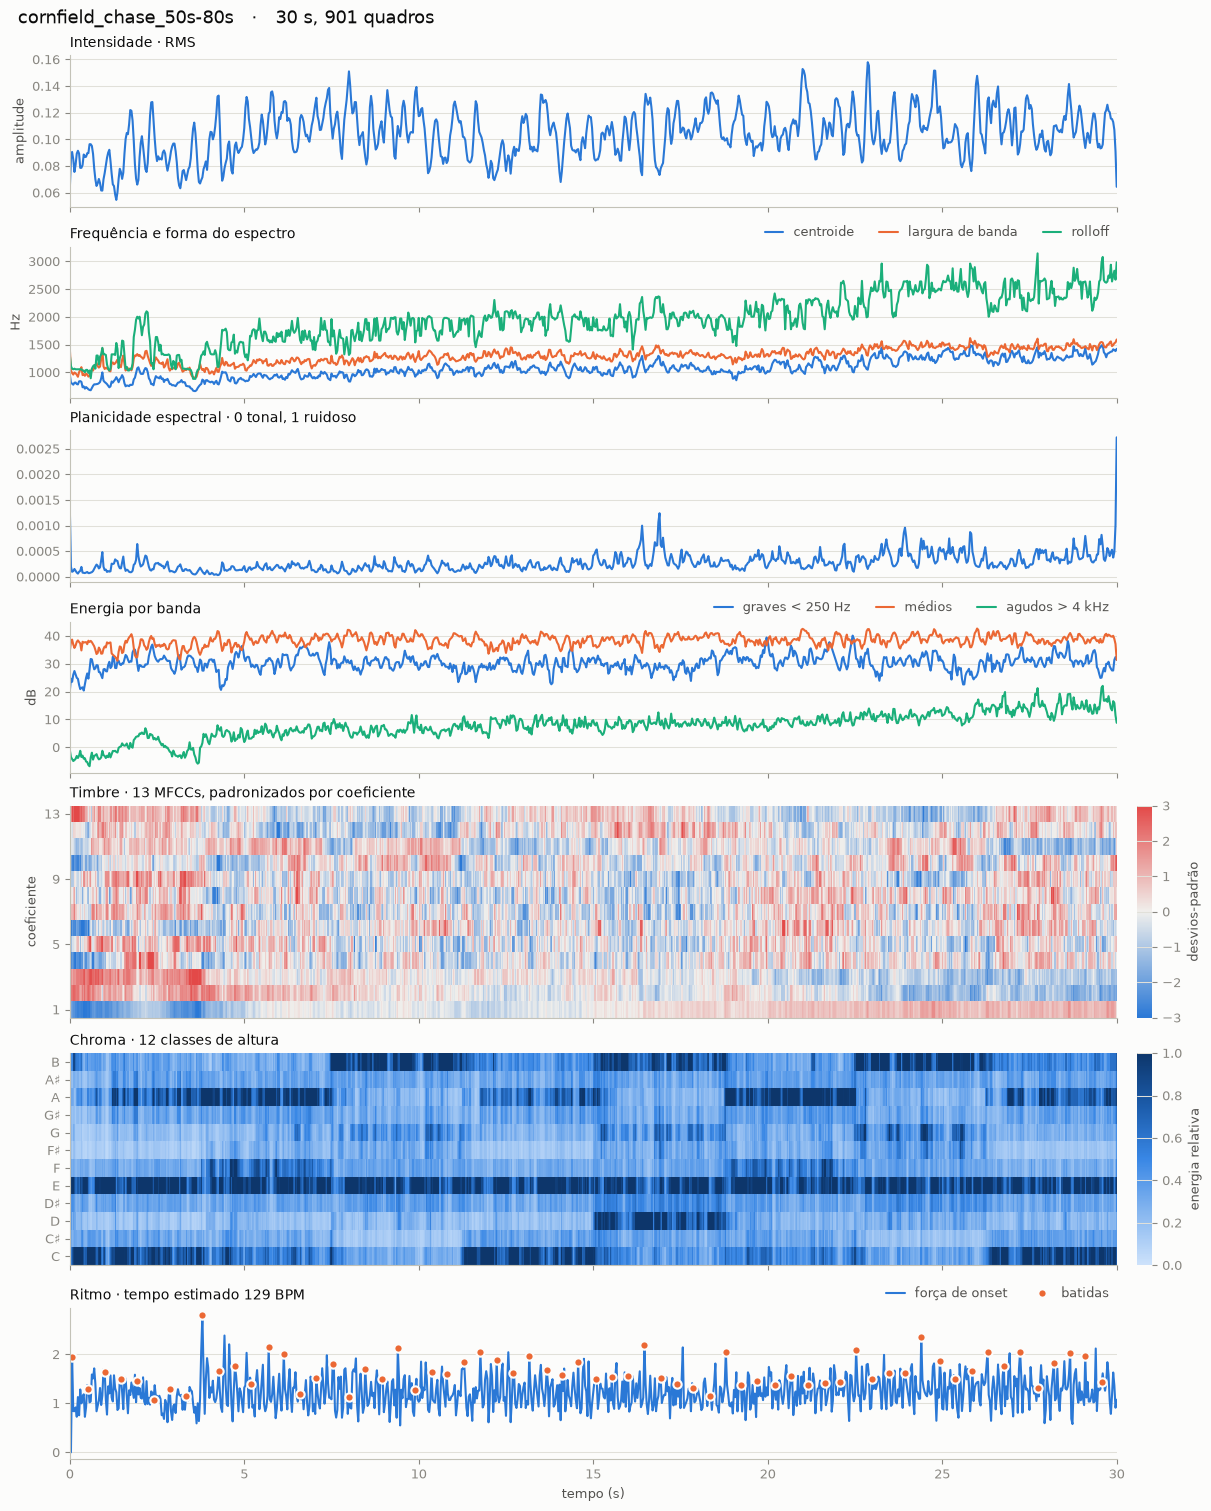

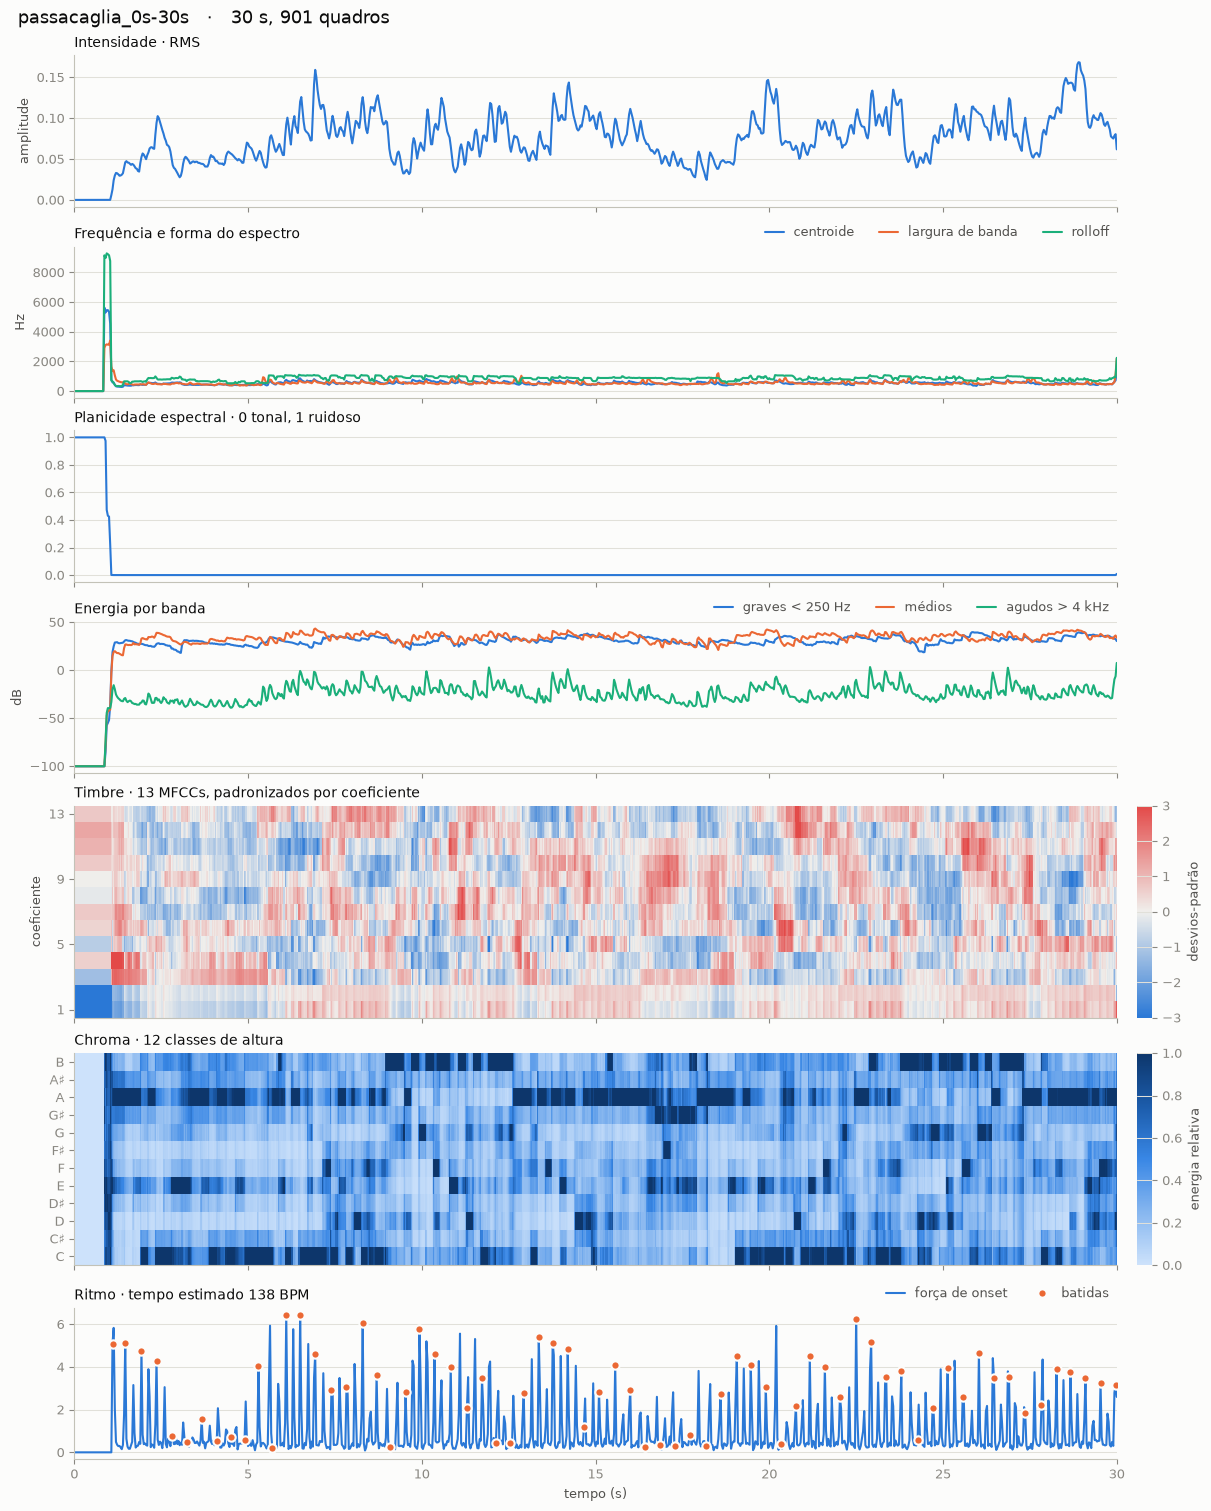

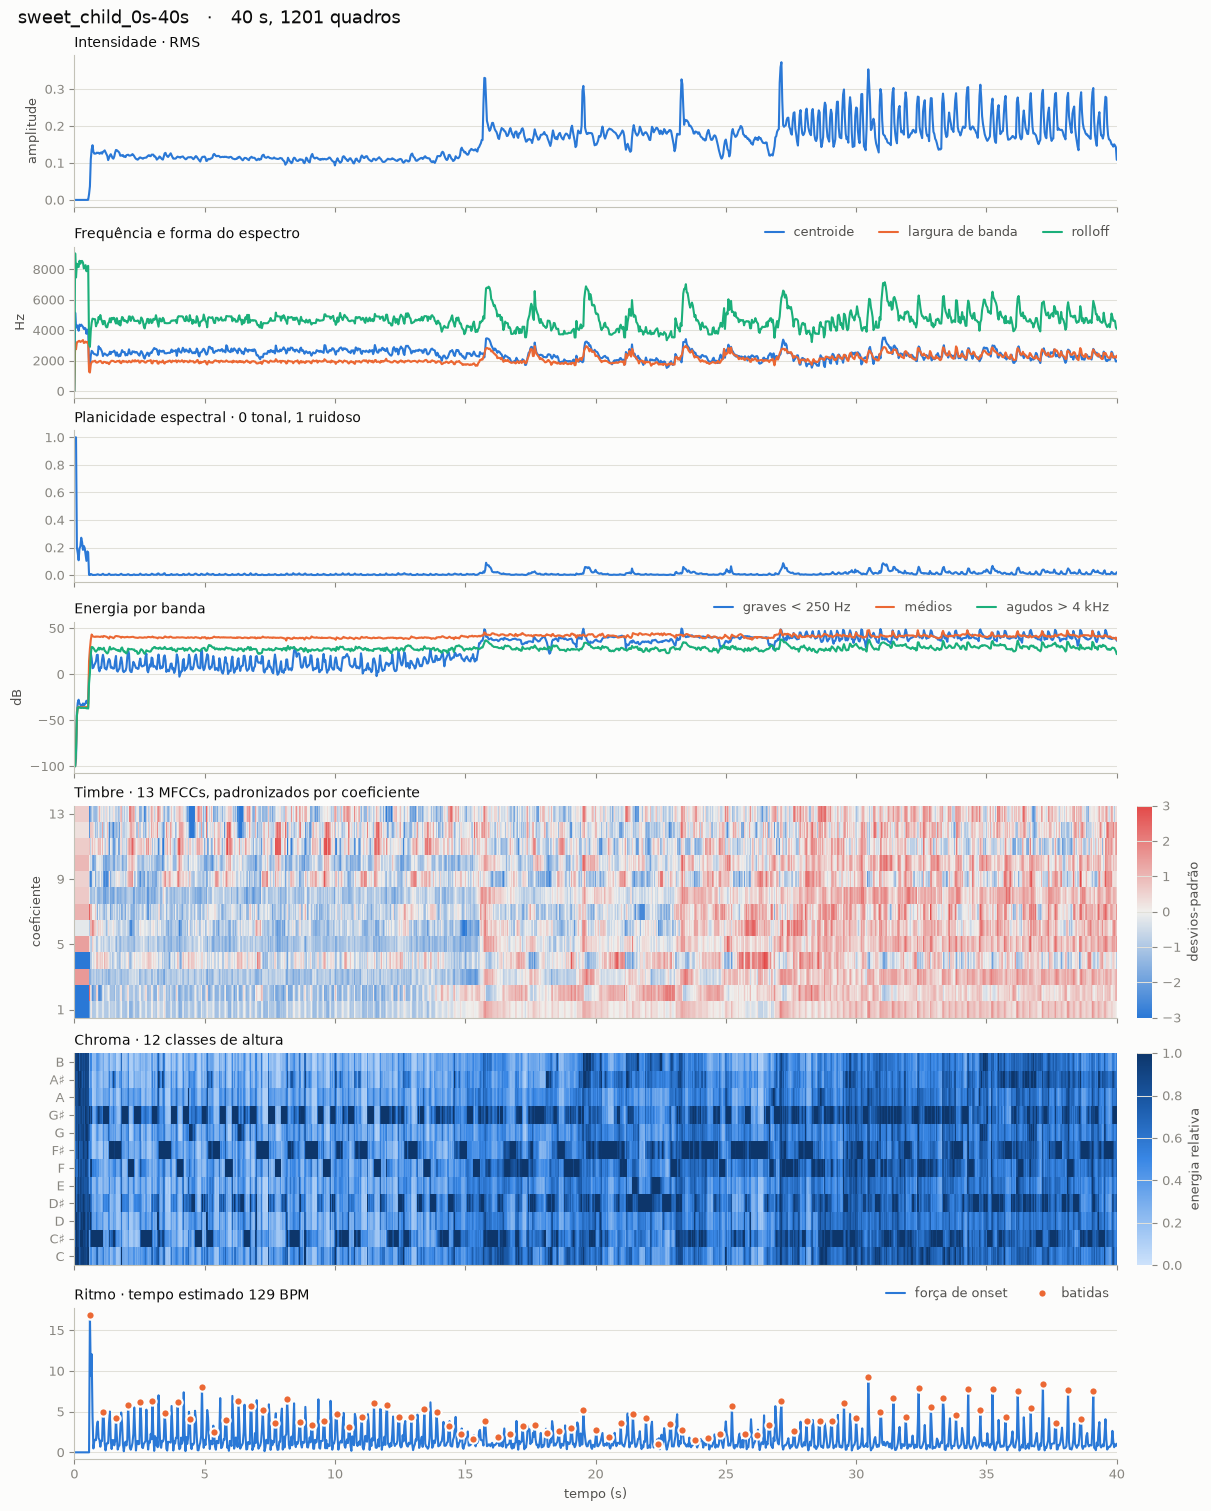

In [4]:
for path in songs:
    plot_track(path.stem, features[path.stem])

## Sinais sintéticos

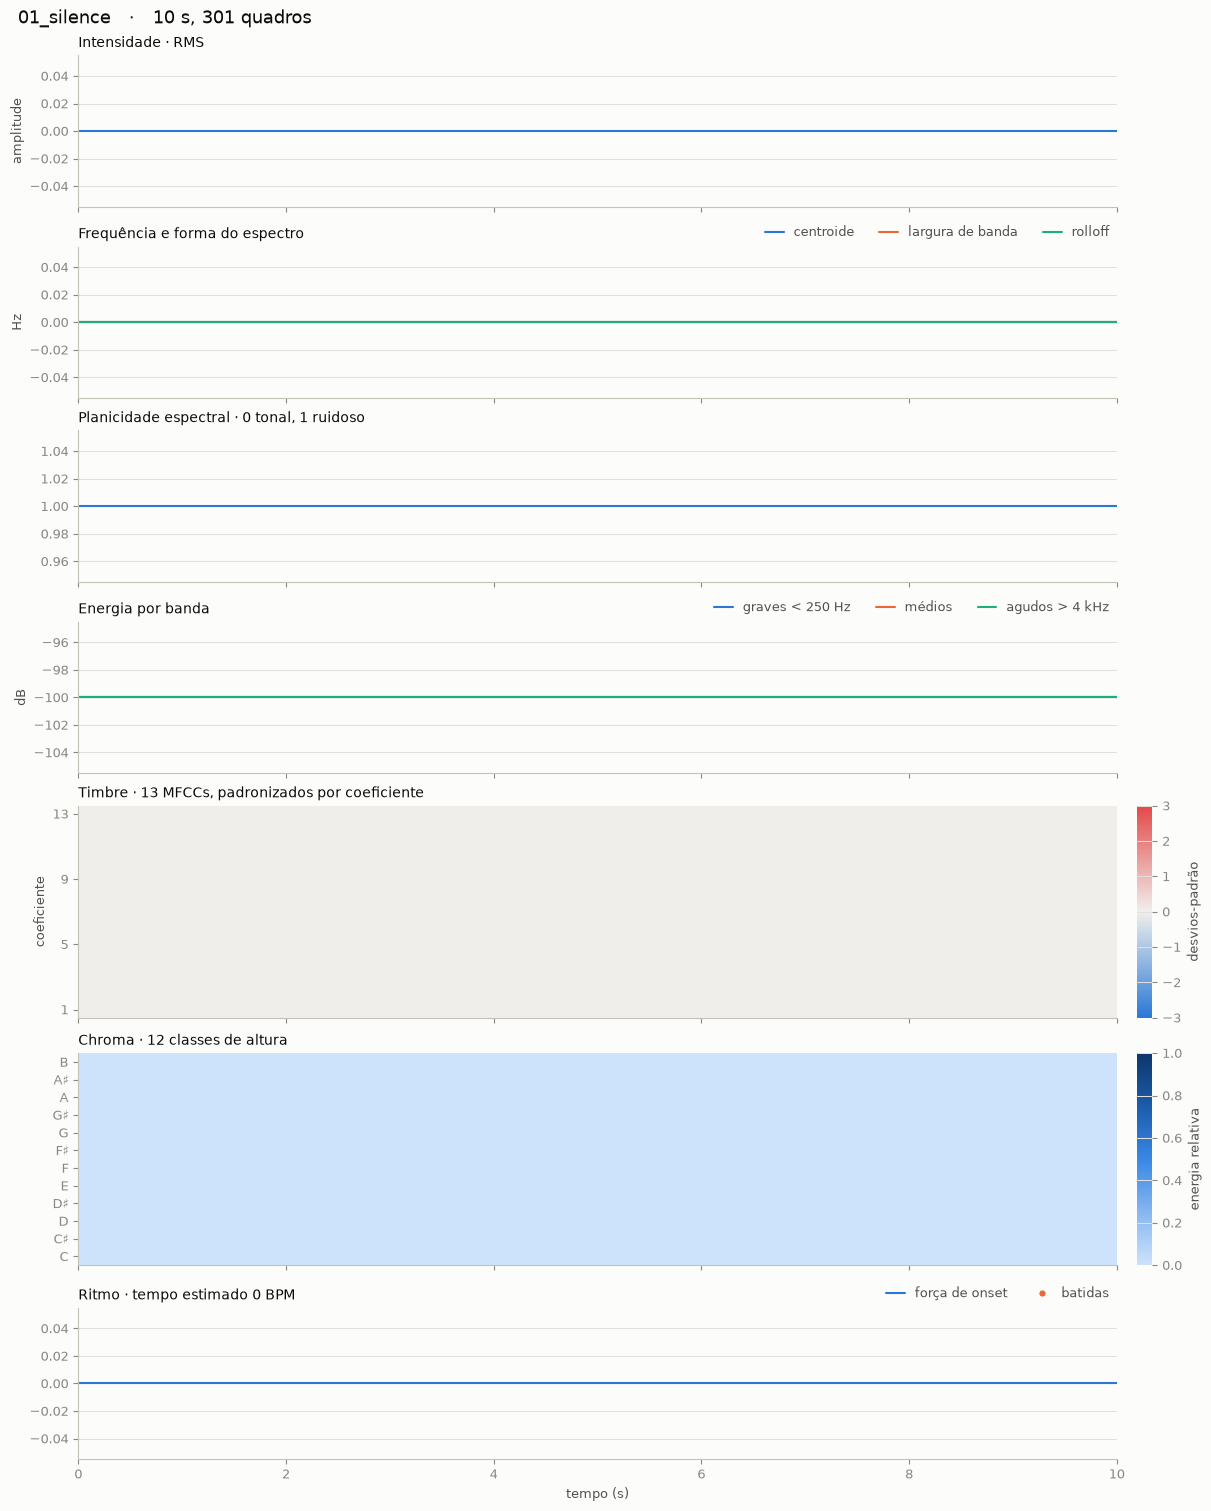

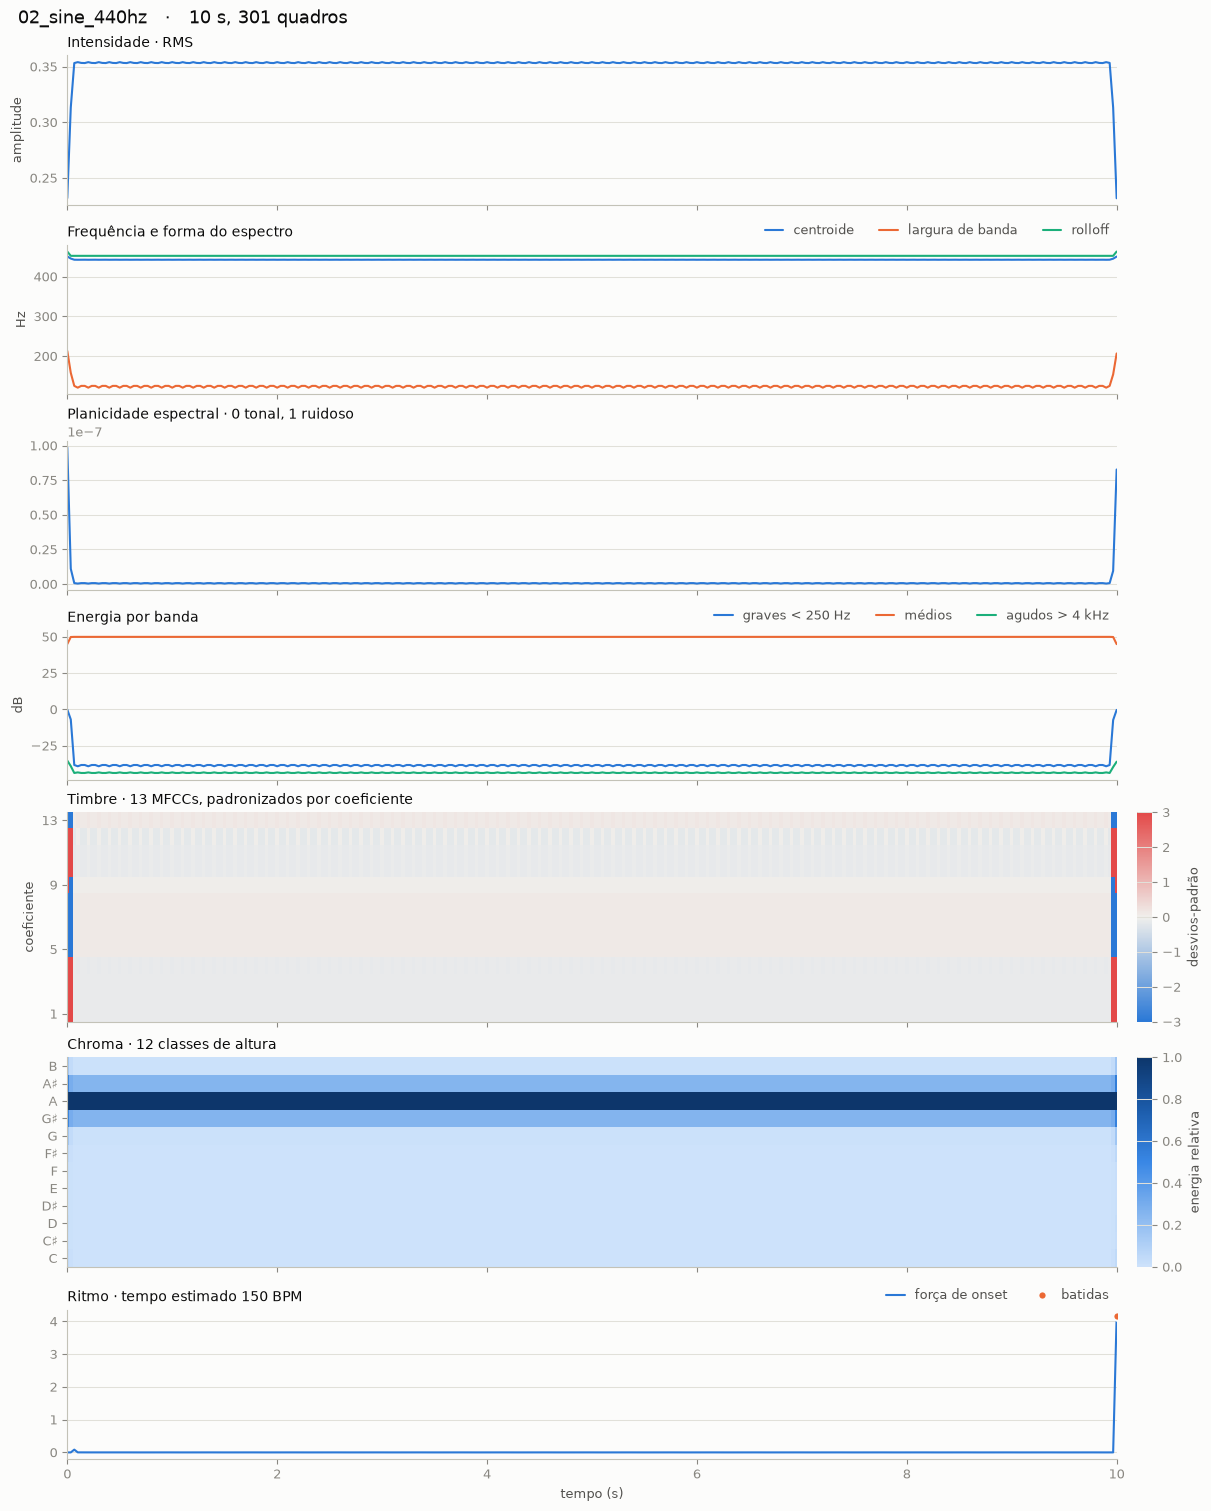

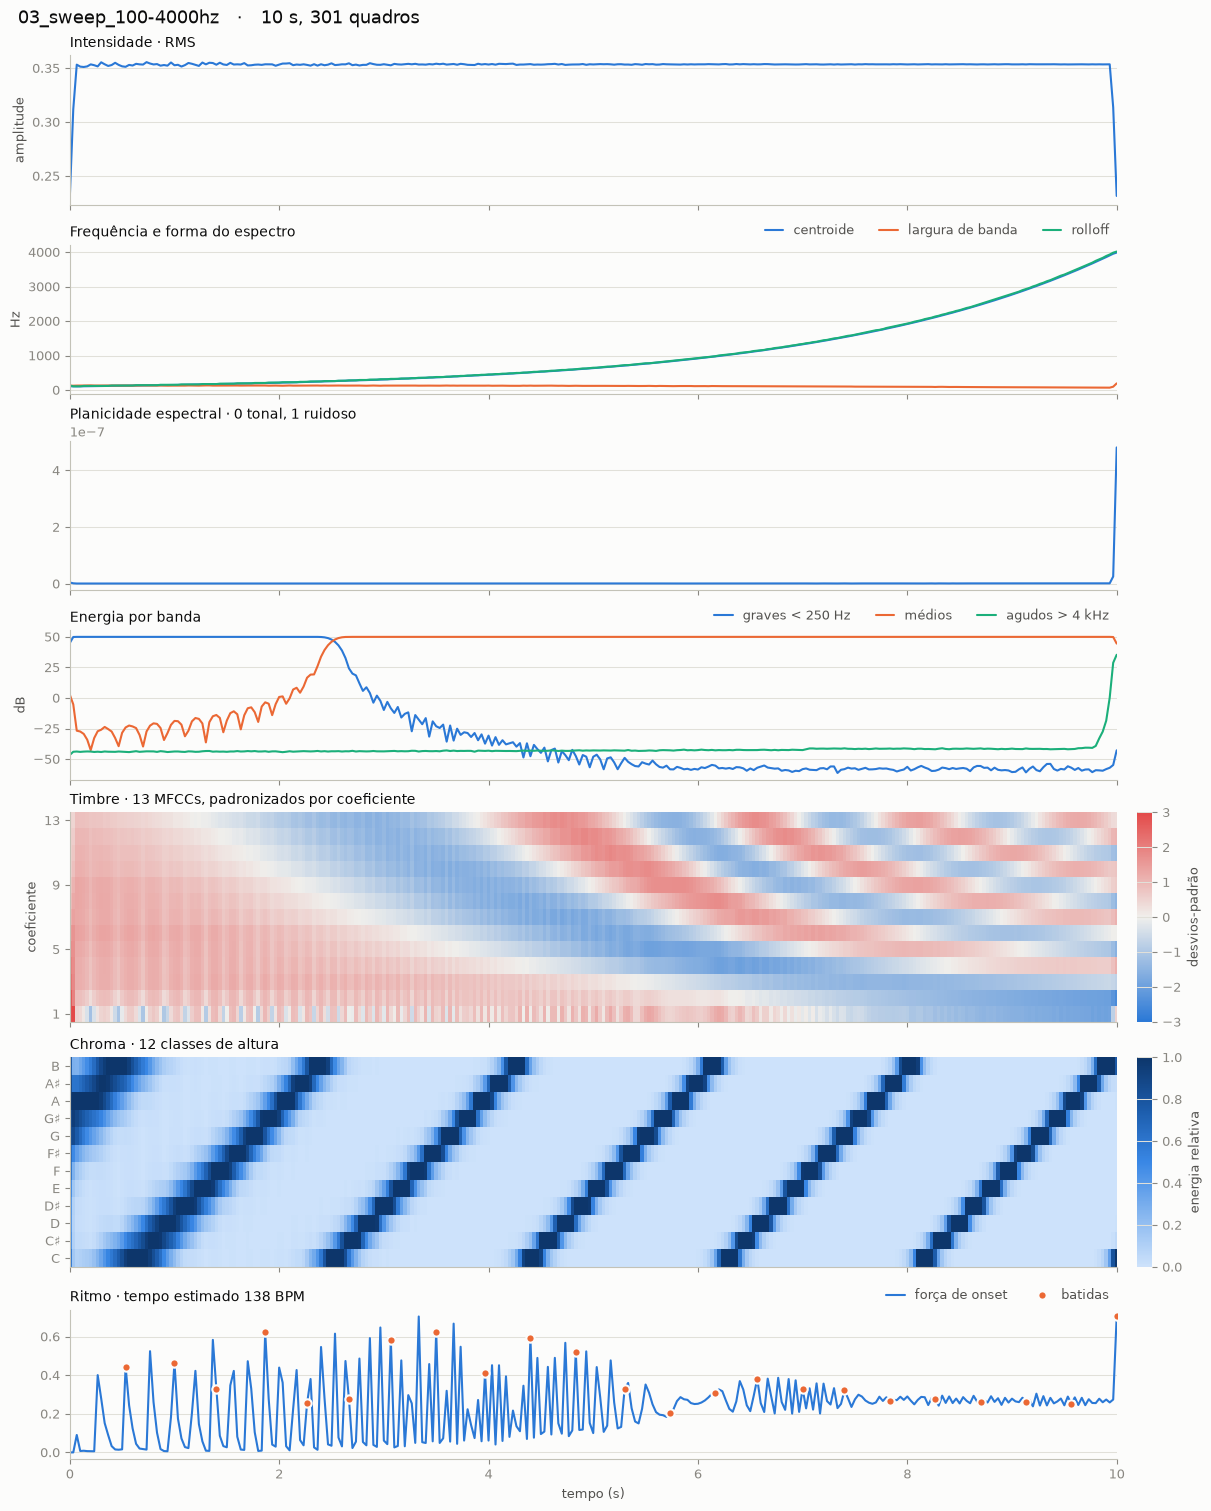

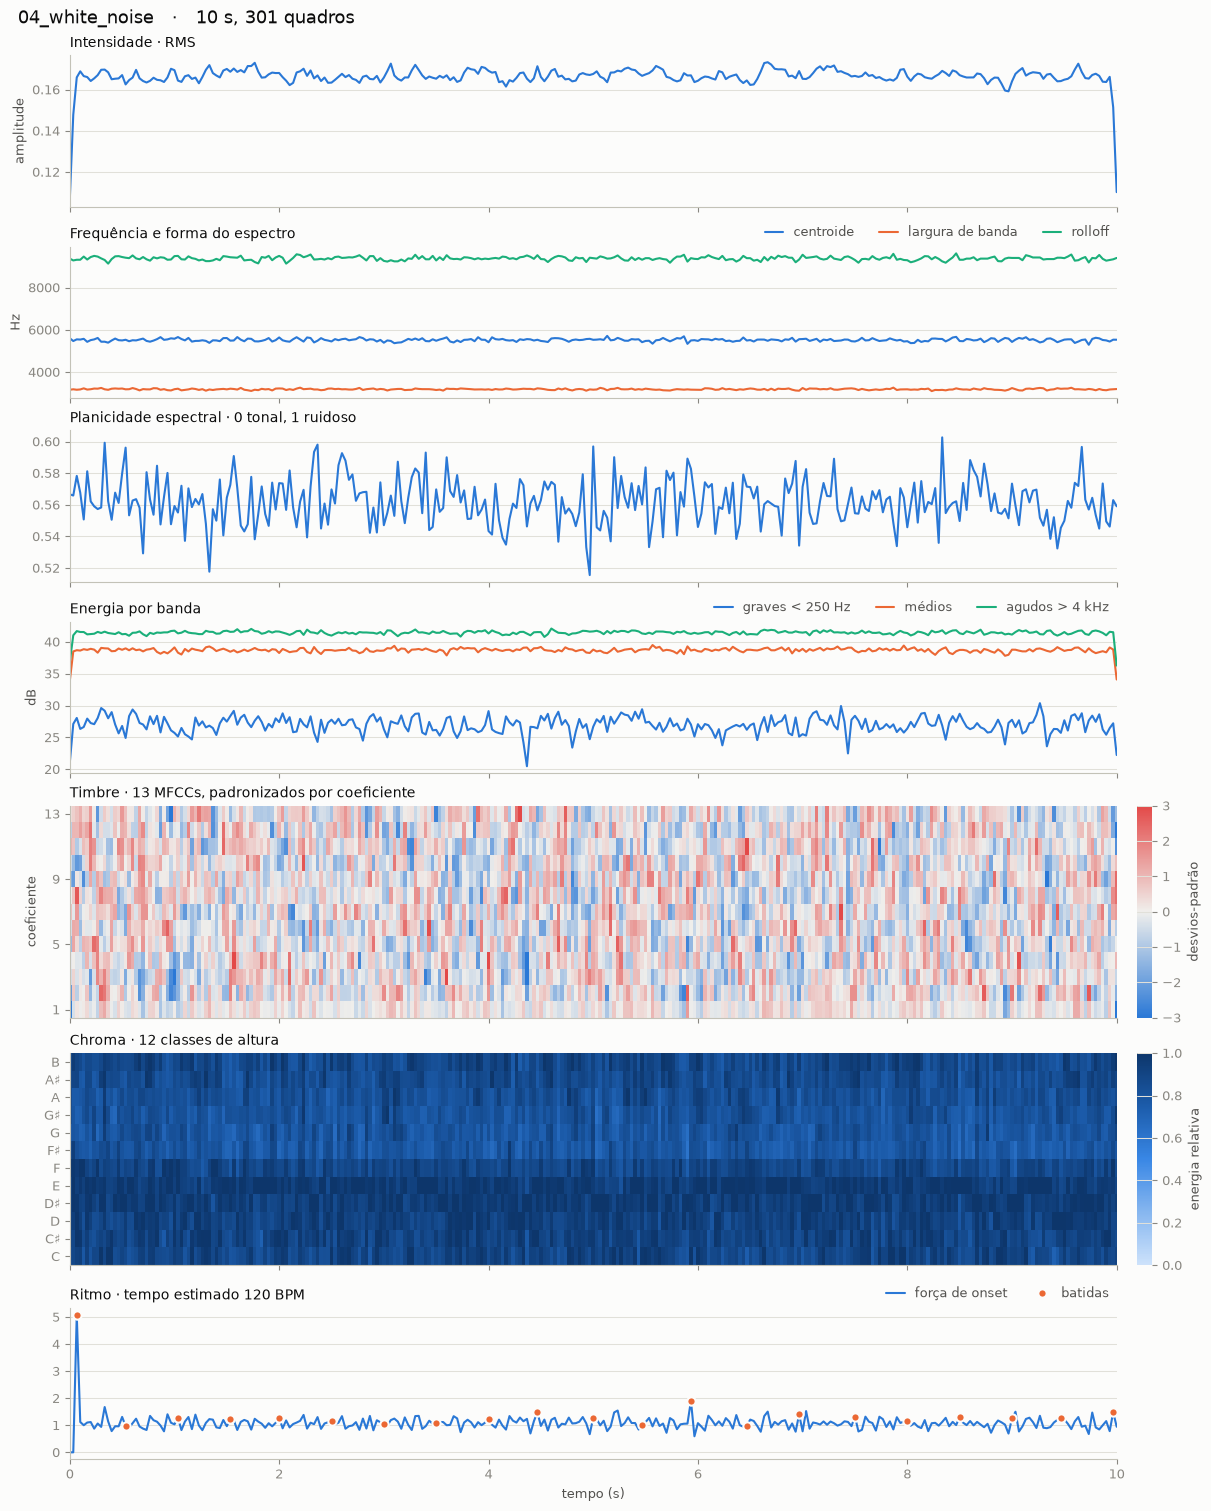

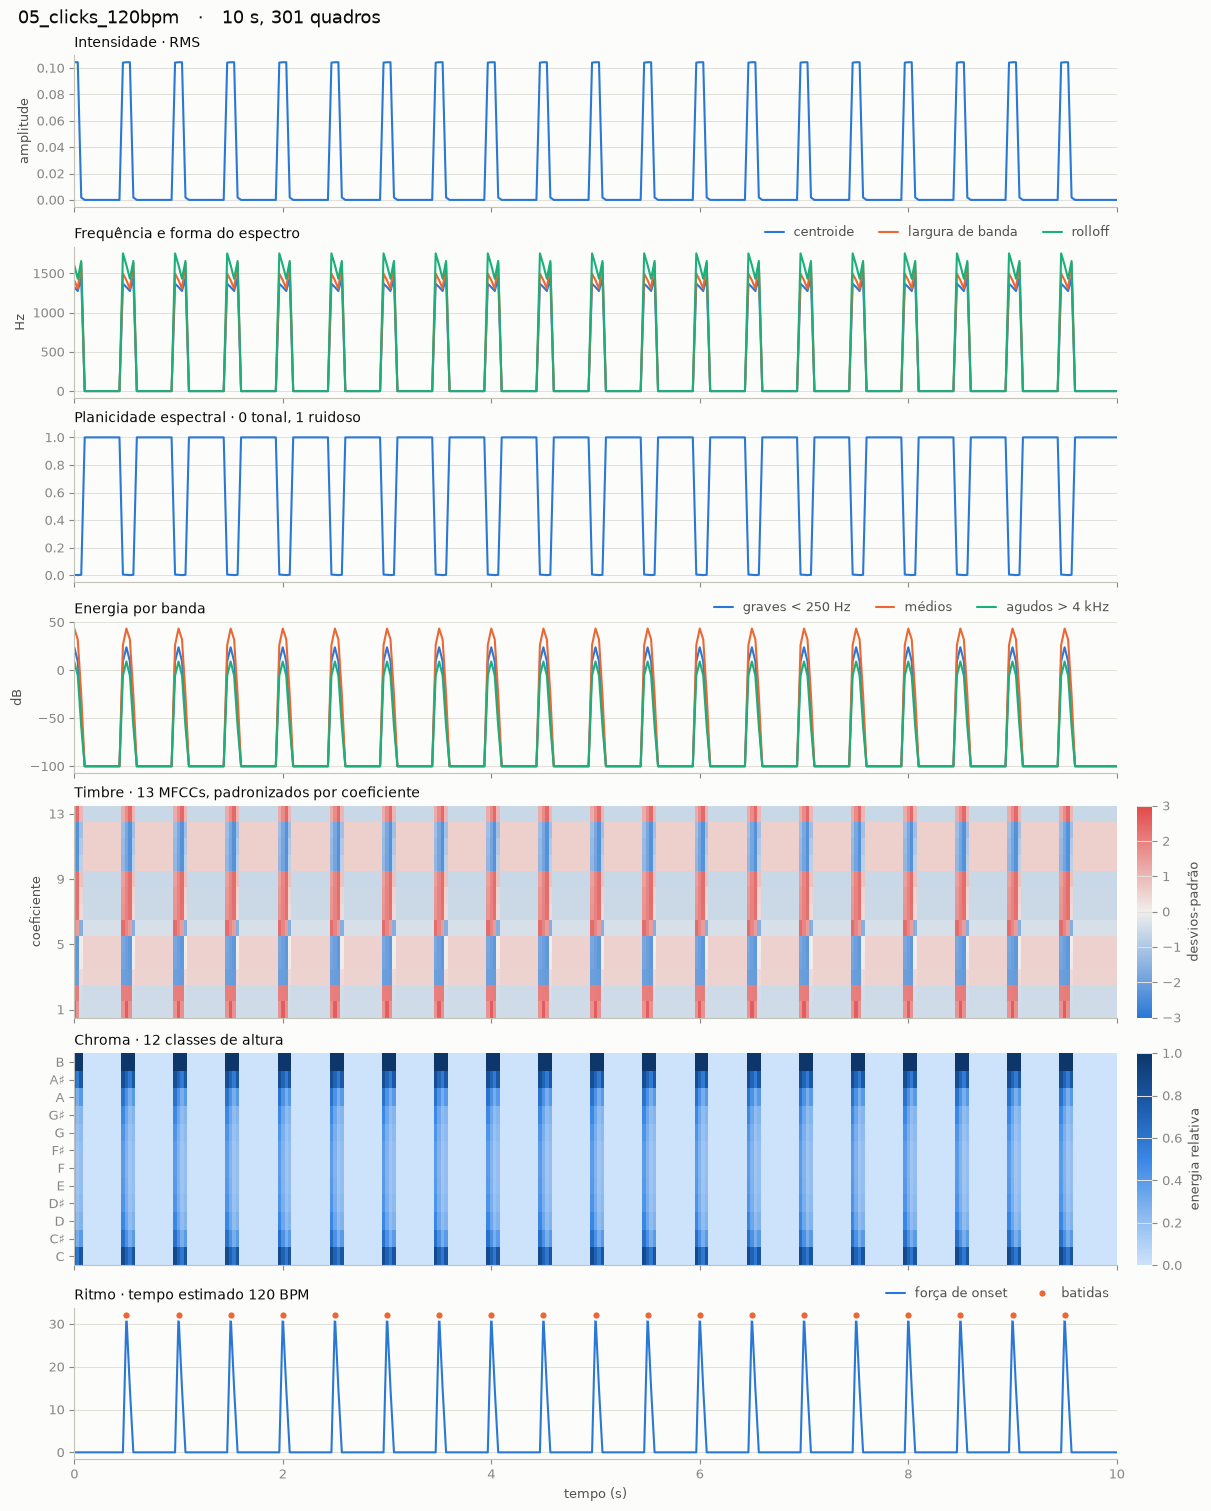

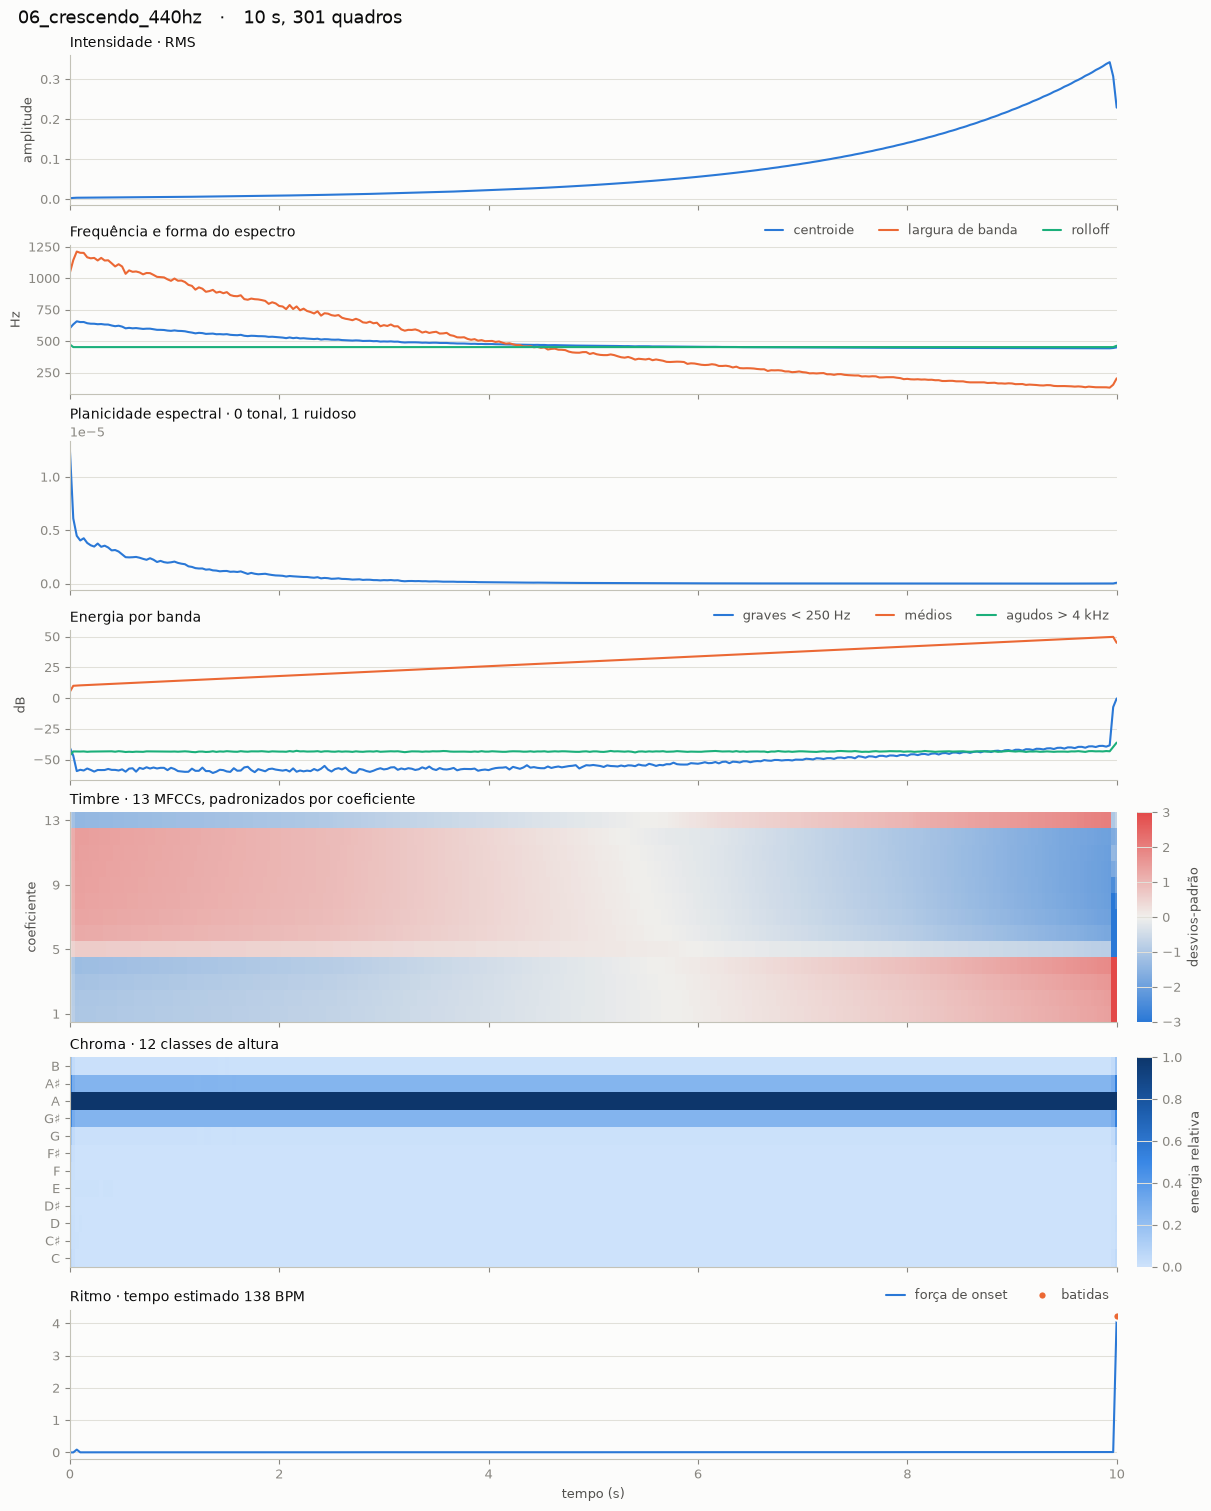

In [5]:
for path in synthetic:
    plot_track(path.stem, features[path.stem])

## Conferência com os sinais sintéticos

Cada sinal sintético tem um comportamento esperado conhecido. A tabela abaixo confere um por um:

| Sinal | O que se espera |
|---|---|
| silêncio | RMS praticamente zero |
| senoide de 440 Hz | classe de altura dominante = A (Lá) |
| varredura 100 Hz → 4 kHz | centroide crescente (correlação de Spearman com o tempo > 0,95) |
| ruído branco | planicidade alta (mediana > 0,3) |
| cliques a 120 BPM | picos de onset a cada 0,5 s, com erro menor que um quadro, e tempo estimado de 120 BPM |
| crescendo | RMS crescente (correlação de Spearman com o tempo > 0,95) |

In [6]:
def frame_times(f):
    return np.arange(len(f["rms"])) / config.fps


f = features["01_silence"]
silence = f["rms"].max()

f = features["02_sine_440hz"]
sine_class = PITCH_CLASSES[np.argmax([f[f"chroma_{i}"].mean() for i in range(12)])]

f = features["03_sweep_100-4000hz"]
sweep_rho = spearmanr(frame_times(f), f["spectral_centroid"]).statistic

f = features["04_white_noise"]
noise_flatness = np.median(f["spectral_flatness"])

f = features["05_clicks_120bpm"]
peaks, _ = find_peaks(f["onset_strength"], height=0.5 * f["onset_strength"].max())
intervals = np.diff(peaks) / config.fps
clicks_ok = np.all(np.abs(intervals - 0.5) < 1 / config.fps) and abs(f["tempo_bpm"] - 120) < 1

f = features["06_crescendo_440hz"]
crescendo_rho = spearmanr(frame_times(f), f["rms"]).statistic

checks = pd.DataFrame([
    ("01_silence", "RMS máximo", f"{silence:.2e}", silence < 1e-4),
    ("02_sine_440hz", "classe dominante", sine_class, sine_class == "A"),
    ("03_sweep_100-4000hz", "Spearman(tempo, centroide)", f"{sweep_rho:.3f}", sweep_rho > 0.95),
    ("04_white_noise", "planicidade mediana", f"{noise_flatness:.3f}", noise_flatness > 0.3),
    ("05_clicks_120bpm", "intervalo entre picos / tempo",
     f"{intervals.min():.3f}–{intervals.max():.3f} s, {len(peaks)} picos / {features['05_clicks_120bpm']['tempo_bpm']:.1f} BPM",
     clicks_ok),
    ("06_crescendo_440hz", "Spearman(tempo, RMS)", f"{crescendo_rho:.3f}", crescendo_rho > 0.95),
], columns=["sinal", "medida", "valor", "ok"])
checks

,sinal,medida,valor,ok
0,01_silence,RMS máximo,0.00e+00,True
1,02_sine_440hz,classe dominante,A,True
2,03_sweep_100-4000hz,"Spearman(tempo, centroide)",1.000,True
3,04_white_noise,planicidade mediana,0.561,True
4,05_clicks_120bpm,intervalo entre picos / tempo,"0.500–0.500 s, 19 picos / 120.0 BPM",True
5,06_crescendo_440hz,"Spearman(tempo, RMS)",1.000,True


### Varredura: centroide medido × frequência da senoide

A varredura é exponencial, f(t) = 100 · 40^(t/10) Hz (os mesmos valores de `data/synthetic_audio_generator.py`). Em eixo logarítmico ela vira uma reta, e o centroide deve acompanhá-la.

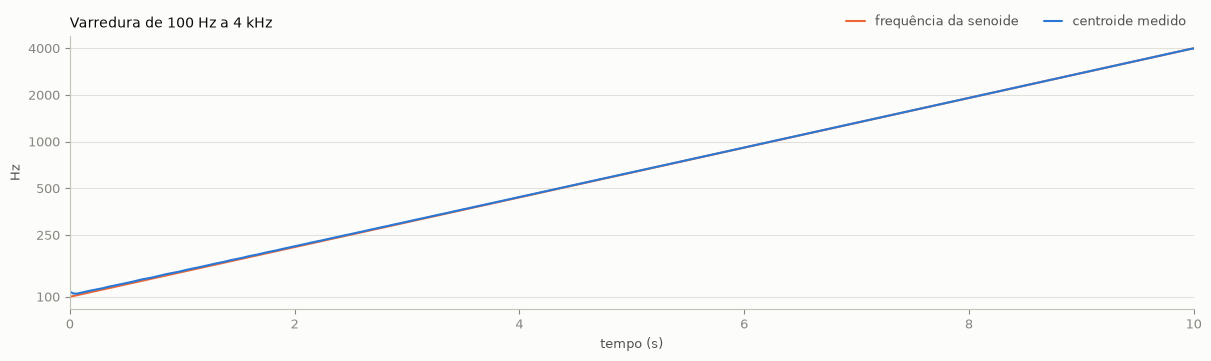

In [7]:
f = features["03_sweep_100-4000hz"]
t = frame_times(f)
expected = 100 * (4000 / 100) ** (t / 10)

fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
ax.plot(t, expected, color=SERIES[1], label="frequência da senoide")
ax.plot(t, f["spectral_centroid"], color=SERIES[0], label="centroide medido")
ax.set_yscale("log")
ax.set_yticks([100, 250, 500, 1000, 2000, 4000], ["100", "250", "500", "1000", "2000", "4000"])
ax.minorticks_off()
ax.set_xlim(t[0], t[-1])
ax.set_xlabel("tempo (s)")
style_panel(ax, "Varredura de 100 Hz a 4 kHz", "Hz", legend=True)
plt.show()

## Observações para o mapeamento dos próximos passos

- **Silêncio tem planicidade 1**, o valor de ruído puro. Em silêncio digital (o sinal 01 e os intervalos entre cliques) todas as frequências têm a mesma energia, zero, e o espectro fica "plano". Se a fricção γ for ligada direto à planicidade, o silêncio vai se comportar como ruído. Vale ponderar a planicidade pelo RMS.
- **O tempo estimado não é confiável em sinais sem ritmo.** O crescendo, que não tem batida nenhuma, sai com 138 BPM.
- **O clique em t = 0 não gera pico de onset**, porque a força de onset mede a variação em relação ao quadro anterior, e o primeiro quadro não tem com quem comparar. Por isso a trilha tem 20 cliques e 19 picos.